In [19]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pickle
import mne
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
import datetime as dt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# 0. Define Colors

In [3]:
col_list = ["#377eb8", "#e41a1c"]

# 1.Functions for
## a) creating average amplitude for each independent session

In [4]:
def create_averages(sess_list, data_origin,prefix_calib,prefix_copy,file_extension):
    #creates an average of the independent sessions - outputs two files
    #     - Pickle file: create array sessions of shape(sess-1, 2(target/non_target), #of electrodes, #of timepoint))
    #     - csv: with time stamp for the samples
    #creates an average amplitude of each tactilo target and non-target 
    picks= ["Fz","Fc1","Fc2","C3","Cz","C4","Pz"]
    sess_averages = np.zeros((len(sess_list),2,len(picks),462)) # create array sessions, (sess-1,[target, nontarget],(["Fz","Fc1","Fc2","C3","Cz","C4","Pz"], (timepoints))
    num_tactilos = 4 if "4" in prefix_calib else 6
    mean_amplitudes = pd.DataFrame(columns=["Session","Electrode","Tactilo","Mean Amplitude","Condition"])
    for i,sess in enumerate(sess_list):
        data_paths = []
        data_paths.append(data_origin + prefix_calib + str(sess).zfill(3) + ".pickle")
        data_paths.append(data_origin + prefix_copy + str(sess).zfill(3) + ".pickle")

        mne.set_log_level('WARNING')
        for data_path in data_paths:
            if 'Calib' in data_path:
                raw_list =[]
            with open(data_path, "rb") as file:
                data_tuple = pickle.load(file)
                raw_list += data_tuple[0]
            if 'Calib' in data_path:
                continue
            
            for k, raw in enumerate(raw_list):
                raw_list[k] = raw.pick(picks).filter(l_freq=0.1, h_freq=40) # band-pass filter
                #raw_list[k] = raw.pick(picks) #no band-pass filter

            raw = mne.concatenate_raws(raw_list)
            events, event_id = mne.events_from_annotations(raw)
            event_id.pop('10')
            epochs= mne.Epochs(raw, events, event_id=event_id, tmin=-0.1, tmax=0.8, preload=True,picks=picks,event_repeated='merge',baseline=(None,0),reject=dict(eeg=100e-6))  # timewindow -0.85 so its' 0.8 after resampling baseline=(-0.100,0)
            epochs = epochs.pick_channels(picks,ordered = True) # assure channels are in the same order as picks
            
            for tactilo in range(1,num_tactilos+1):
                target_tac = '1/10'+str(tactilo)
                df = pd.DataFrame((epochs[target_tac].average()._data*1e6).T)
                df.index = epochs.times
                for electrode,amp in enumerate(df[0.35: 0.6].mean().to_list()): # adjust time of interest alternativ: # average between 350 -600ms
                #for electrode,amp in enumerate(df[0.2: 0.7].max().to_list()): # adjust time of interest alternativ: # maximum value between 200-700ms
                    mean_amplitudes.loc[len(mean_amplitudes)] =[sess,picks[electrode],str(tactilo),amp,"Target"]
            for tactilo in range(1,num_tactilos+1):
                non_target_tac = '0/10'+str(tactilo)
                df = pd.DataFrame((epochs[non_target_tac].average()._data*1e6).T)
                df.index = epochs.times
                for electrode,amp in enumerate(df[0.35: 0.6].mean().to_list()):
                    mean_amplitudes.loc[len(mean_amplitudes)] =[sess,picks[electrode],str(tactilo),amp,"nonTarget"]
                
             
            nt_avg = epochs['0'].average()._data*1e6 #mne data in Volt! create evoked
            t_avg = epochs['1'].average()._data*1e6
            np.copyto(sess_averages[i,0,:,:],t_avg)
            np.copyto(sess_averages[i,1,:,:],nt_avg)
    print(r"created_data_LIS\average_amplitudes_350_600_"+file_extension+".csv")
    mean_amplitudes.to_csv(r"created_data_LIS\average_amplitudes_350_600_"+file_extension+".csv",index=False)
    np.savetxt(r"created_data_LIS\epoch_timetstamps_" + file_extension +".csv"  , epochs.times, delimiter=",")
    with open(r"created_data_LIS\average_amplitudes_" + file_extension +".pickle","wb") as file:
        pickle.dump(sess_averages, file)



## b)  amplitude plots

In [5]:
def plot_amplitude(amp_array,timestamps,electrodes_to_plot,title,y_lim):
    picks= ["Fz","Fc1","Fc2","C3","Cz","C4","Pz"]
    t= amp_array[:,0]
    t_avg = amp_array[:,0].mean(axis=0)
    nt =amp_array[:,1]
    nt_avg = amp_array[:,1].mean(axis=0)
    for e in electrodes_to_plot:
        fig, ax = plt.subplots(1, 1, figsize=(6, 5), sharey=True)
        electrode = picks.index(e)
        ax.plot(timestamps, t_avg[electrode], label="Target", c=col_list[1])
        ax.plot(timestamps, nt_avg[electrode], label="Non-Target", c=col_list[0])
        t_std = np.std(t[:, electrode, :], axis=0)
        nt_std = np.std(nt[:, electrode, :], axis=0)
        t_ci = 1.96 * t_std / np.sqrt(t.shape[0])
        nt_ci = 1.96 * nt_std / np.sqrt(nt.shape[0])
        ax.fill_between(timestamps, t_avg[electrode] - t_ci, t_avg[electrode] + t_ci, alpha=0.3, color=col_list[1])
        ax.fill_between(timestamps, nt_avg[electrode] - nt_ci, nt_avg[electrode] + nt_ci, alpha=0.3,
                             color=col_list[0])
        ax.axvline(x=0, c='k', lw=0.5)
        ax.axhline(y=0, c='k', lw=0.5)
        ax.axvspan(0.35, 0.6, facecolor="#808080", alpha=0.3) # grauer balken makiert average bereich
        ax.set_xlabel("seconds")
        ax.set_ylabel("µV")
        ax.margins(x=0)
        ax.set_title
        ax.set_ylim(y_lim)

        #ax.legend(title="Average of  sessions with  "+title + " at " + e +" (n=" + str(t.shape[0]) + ")", loc='center', bbox_to_anchor=(0.5, 1.16), ncol=2)
        ax.legend(title="Average of all sessions at " + e +" (n=" + str(t.shape[0]) + ")", loc='center', bbox_to_anchor=(0.5, 1.16), ncol=2)
        # fig.suptitle("Average over all sessions")
        fig.tight_layout()
        # plt.show()
        plt.savefig(r"created_data_LIS\average_"+e+"_Session_"+title+".svg", format="svg", transparent=True)


## c) single session amplitude

In [6]:
def plot_amplitude_sessionwise(sess_list, data_origin,prefix_calib,prefix_copy,file_extension, picks= ["Fz","Fc1","Fc2","C3","Cz","C4","Pz"]):
    for i,sess in enumerate(sess_list):
        data_paths = []
        data_paths.append(data_origin + prefix_calib + str(sess).zfill(3) + ".pickle")
        data_paths.append(data_origin + prefix_copy + str(sess).zfill(3) + ".pickle")

        num_tactilos = 4 if "4" in prefix_calib else 6
        mne.set_log_level('WARNING')

        for data_path in data_paths:
            if 'Calib' in data_path:
                raw_list =[]
            with open(data_path, "rb") as file:
                data_tuple = pickle.load(file)
                raw_list += data_tuple[0]
            if 'Calib' in data_path:
                continue

            for k, raw in enumerate(raw_list):
                raw_list[k] = raw.pick(picks).filter(l_freq=0.1, h_freq=40) # band-pass filter

            raw = mne.concatenate_raws(raw_list)
            events, event_id = mne.events_from_annotations(raw)
            event_id.pop('10')
            epochs= mne.Epochs(raw, events, event_id=event_id, tmin=-0.1, tmax=0.8, preload=True,picks=picks,event_repeated='merge',baseline=(None,0),reject=dict(eeg=100e-6))  # timewindow -0.85 so its' 0.8 after resampling baseline=(-0.100,0)
            epochs = epochs.pick_channels(picks,ordered = True) # assure channels are in the same order as picks


            nt = epochs['0']._data*1e6 #mne data in Volt! create evoked
            t = epochs['1']._data*1e6
            nt_avg = epochs['0'].average()._data*1e6 #mne data in Volt! create evoked
            t_avg = epochs['1'].average()._data*1e6

            timestamps = epochs.times
            for e in picks:
                fig, ax = plt.subplots(1, 1, figsize=(6, 5))
                electrode = picks.index(e)
                ax.plot(timestamps, t_avg[electrode], label="Target", c=col_list[1])
                ax.plot(timestamps, nt_avg[electrode], label="Non-Target", c=col_list[0])
                t_std = np.std(t[:, electrode, :], axis=0)
                nt_std = np.std(nt[:, electrode, :], axis=0)
                t_ci = 1.96 * t_std / np.sqrt(t.shape[0])
                nt_ci = 1.96 * nt_std / np.sqrt(nt.shape[0])
                ax.fill_between(timestamps, t_avg[electrode] - t_ci, t_avg[electrode] + t_ci, alpha=0.3, color=col_list[1])
                ax.fill_between(timestamps, nt_avg[electrode] - nt_ci, nt_avg[electrode] + nt_ci, alpha=0.3,
                                     color=col_list[0])
                ax.axvline(x=0, c='k', lw=0.5)
                ax.axhline(y=0, c='k', lw=0.5)
                #ax.axvspan(0.35, 0.6, facecolor="#808080", alpha=0.3) # grauer balken makiert average bereich
                ax.set_xlabel("seconds")
                ax.set_ylabel("µV")
                ax.set_ylim(-4,8)
                ax.margins(x=0)

                ax.legend(title="Average of Session " + str(sess) +" at " + e +" (n=" + str(t.shape[0]) + ")", loc='center', bbox_to_anchor=(0.5, 1.16), ncol=2)
                # fig.suptitle("Average over all sessions")
                fig.tight_layout()
                # plt.show()
                plt.savefig(r"created_data_LIS\SessionwiseERP\ERP_"+e+"_Session_"+str(sess)+ "_" + file_extension + ".svg", format="svg", transparent=True)


## d) R² -plots

In [7]:
def plot_r2(sess_list, data_origin,prefix_calib,prefix_copy,file_extension, picks= ["Fz","Fc1","Fc2","C3","Cz","C4","Pz"]):

    for i,sess in enumerate(sess_list):
        data_paths = []
        data_paths.append(data_origin + prefix_calib + str(sess).zfill(3) + ".pickle")
        data_paths.append(data_origin + prefix_copy + str(sess).zfill(3) + ".pickle")

        mne.set_log_level('WARNING')
        for data_path in data_paths:
            if 'Calib' in data_path:
                raw_list =[]
            with open(data_path, "rb") as file:
                data_tuple = pickle.load(file)
                raw_list += data_tuple[0]
            if 'Calib' in data_path:
                continue

            for k, raw in enumerate(raw_list):
                raw_list[k] = raw.pick(picks).filter(l_freq=0.1, h_freq=40) # band-pass filter

            raw = mne.concatenate_raws(raw_list)
            events, event_id = mne.events_from_annotations(raw)
            event_id.pop('10')
            epochs= mne.Epochs(raw, events, event_id=event_id, tmin=-0.1, tmax=0.8, preload=True,picks=picks,event_repeated='merge',baseline=(None,0),reject=dict(eeg=100e-6))  # timewindow -0.85 so its' 0.8 after resampling baseline=(-0.100,0)
            epochs = epochs.pick_channels(picks,ordered = True) # assure channels are in the same order as picks

            new_event_id = {} # empty dictionary
            for key, value in epochs.event_id.items(): # set all targets to 1, non_targets to 0
                new_event_id[value] = 0 if key[0] == "0" else 1

            event_labels = pd.DataFrame(epochs.events[:, 2])
            event_labels.replace(new_event_id, inplace=True)
            y = np.array(event_labels.loc[((event_labels[0] == 0) | (event_labels[0] == 1))][0])

            getData = epochs.get_data()

            (n_epochs,n_channels,n_samples) = getData.shape

            r_value_mat = np.empty((n_channels,n_samples))
            r_value_mat[:] = np.nan # empty doesn't_avg create an empty array!!
            y_mat = np.tile(y.reshape(1,1,-1).T, (1,n_channels, n_samples))


            for timepoint in range(n_samples):
                for electrode in range(n_channels):
                    slope, intercept, r_value, p_value, std_err = stats.linregress(getData[:,electrode, timepoint],y_mat[:,electrode, timepoint])
                    r_value_mat[electrode, timepoint] = r_value

            r2_value_mat = np.square(r_value_mat)

            fig, ax = plt.subplots(figsize=(10, 7))
            xticks = xticks = np.linspace(0, n_samples - 1, round(n_samples / 51.2) + 1, dtype=np.int)
            xticklabels = np.around(np.arange(round(epochs.tmin,3),round(epochs.tmax,3), 0.1),3).tolist()
            sns.heatmap(r2_value_mat, cmap="viridis", fmt="", ax=ax, yticklabels=picks, xticklabels=xticklabels)
            ax.set_xticks(xticks)
            ax.set_xticklabels(xticklabels, rotation=45)
            ax.set_xlabel("seconds")
            ax.set_ylabel("Electrodes")
            ax.set_title("R² of session "+str(sess) + " (" + file_extension +")")
            fig.tight_layout()
            # plt.show()
            plt.savefig(r"created_data_LIS\R2\r2_sess"+str(sess)+ "_" + file_extension+".svg", format="svg", transparent=True)



# 2. Create Averages of each session

In [8]:
#4 tactors
sess_list = range(1,31)
data_origin = r"G:\Meine Ablage\PhD\P300\LIS_Paper\Data\mne_raw_4tac"
prefix_calib = r"\4tac_Calib_S"
prefix_copy = r"\4tac_Copy_S"
file_extension = "4_tactors"

create_averages(sess_list, data_origin,prefix_calib,prefix_copy,file_extension)

#6 tactors - legs included
excluded_sessions = [4,7,10,11,12,16,18,19,20,32] #some sessions were training session which followed after the standard protocol (they happend on the same day and are excluded from analysis)
sess_list = [i for i in range(1,26) if i not in excluded_sessions]
data_origin = r"G:\Meine Ablage\PhD\P300\LIS_Paper\Data\mne_raw_6tac"
prefix_calib = r"\Calib_S"
prefix_copy = r"\Free_S"
file_extension = "6_tactors_legs_included"

create_averages(sess_list, data_origin,prefix_calib,prefix_copy,file_extension)

#6 tactors - legs excluded
excluded_sessions = [4,7,10,11,12,16,18,19,20,32] #some sessions were training session which followed after the standard protocol (they happend on the same day and are excluded from analysis)
sess_list = [i for i in range(26,50) if i not in excluded_sessions]
data_origin = r"G:\Meine Ablage\PhD\P300\LIS_Paper\Data\mne_raw_6tac"
prefix_calib = r"\Calib_S"
prefix_copy = r"\Free_S"
file_extension = "6_tactors_legs_excluded"

create_averages(sess_list, data_origin,prefix_calib,prefix_copy,file_extension)


FileNotFoundError: [Errno 2] No such file or directory: 'G:\\Meine Ablage\\PhD\\P300\\LIS_Paper\\Data\\mne_raw_4tac\\4tac_Calib_S001.pickle'

for all 6 tactor sessions together

In [9]:
#6 tactors - all
excluded_sessions = [4,7,10,11,12,16,18,19,20,32] #some sessions were training session which followed after the standard protocol (they happend on the same day and are excluded from analysis)
sess_list = [i for i in range(1,50) if i not in excluded_sessions]
data_origin = r"G:\Meine Ablage\PhD\P300\P300Class\with_Philipp\Data\mne_raw_6tac"
prefix_calib = r"\Calib_S"
prefix_copy = r"\Free_S"
file_extension = "6_tactors_all"

create_averages(sess_list, data_origin,prefix_calib,prefix_copy,file_extension)


created_data_LIS\average_amplitudes_350_600_6_tactors_all.csv


FileNotFoundError: [Errno 2] No such file or directory: 'created_data_LIS\\average_amplitudes_350_600_6_tactors_all.csv'

# 3. Plot the averages

In [ ]:
sections = ["4_tactors","6_tactors_legs_included","6_tactors_legs_excluded"]
titles = ["4 Tactors", r"6 Tactors (Legs Included)", r"6 Tactors (Legs Excluded)"]
for i,file_extension in enumerate(sections):
    with open(r"created_data_LIS\average_amplitudes_" + file_extension +".pickle","rb") as file:
           amp_array = pickle.load(file)
    timestamps = np.genfromtxt(r"created_data_LIS/epoch_timetstamps_" + file_extension +".csv", delimiter=',')
    electrodes_to_plot =["Fz","Cz","Pz"] # ["Fz","Fc1","Fc2","C3","Cz","C4","Pz"]
    y_lim = (-1.3,8)
    plot_amplitude(amp_array,timestamps,electrodes_to_plot,titles[i],y_lim)

In [ ]:
sections = ["6_tactors_all"]
titles = [""]
for i,file_extension in enumerate(sections):
    with open(r"created_data_LIS\average_amplitudes_" + file_extension +".pickle","rb") as file:
           amp_array = pickle.load(file)
    timestamps = np.genfromtxt(r"created_data_LIS/epoch_timetstamps_" + file_extension +".csv", delimiter=',')
    electrodes_to_plot =["Fz","Cz","Pz"] # ["Fz","Fc1","Fc2","C3","Cz","C4","Pz"]
    y_lim = (-1.3,6)
    plot_amplitude(amp_array,timestamps,electrodes_to_plot,titles[i],y_lim)

# 4. Plot amplitudes over time (sessionwise)

In [ ]:
tac4 = pd.read_csv(r"created_data_LIS\average_amplitudes_350_600_4_tactors.csv")
tac6_inlegs = pd.read_csv(r"created_data_LIS\average_amplitudes_350_600_6_tactors_legs_included.csv")
tac6_exlegs = pd.read_csv(r"created_data_LIS\average_amplitudes_350_600_6_tactors_legs_excluded.csv")
tac6_inlegs.Session = tac6_inlegs.Session +100 # add arbitray number to have unique session names
tac6_exlegs.Session = tac6_exlegs.Session +100
all_amp =pd.concat([tac4,tac6_inlegs,tac6_exlegs])

ascending_session_names = dict(zip(all_amp.Session.unique(),range(1,all_amp.Session.unique().size+1)))
all_amp.Session = all_amp["Session"].map(ascending_session_names)
all_amp.groupby(["Session","Condition"]).mean().to_csv(r"created_data_LIS\average_amplitudes_350_600_all.csv")

In [ ]:
tac4 = all_amp.loc[all_amp.Session <31]
tac6_legs = all_amp.loc[(all_amp.Session >=31) &(all_amp.Session <57)]
tac6_no_legs = all_amp.loc[all_amp.Session >=57]
title= ["4 Tactors", "6 Tactors with legs", "6 Tactors without legs"]
x_lim=[(0,31),(30,61),(55,81)]

for i,data_set in enumerate([tac4,tac6_legs, tac6_no_legs]):
    tar_df = data_set.loc[(data_set.Condition == "Target") & (data_set.Electrode == "Cz")].groupby("Session").mean().reset_index(level=[0,0])
    ntar_df = data_set.loc[(data_set.Condition == "nonTarget")& (data_set.Electrode == "Cz")].groupby("Session").mean().reset_index(level=[0,0])

    fig, ax = plt.subplots(figsize = (12,5))
    if i==1:
        ax.axvline(x=42,alpha=0.65,zorder=0,c="k",ls="--",lw=1.3,label ="Electrode SetB" ) # electrode set b    
        ax.axvspan(30.5, 47.5, facecolor="#808080", alpha=0.3,label = "High Intensity Training")
    tar = ax.bar(tar_df["Session"],tar_df["Mean Amplitude"],color = col_list[1], width=0.2,alpha=0.65 ,label = "Target")
    ntar = ax.bar(ntar_df["Session"],ntar_df["Mean Amplitude"],color = col_list[0], width=0.2,alpha=0.65,label = "NonTarget")
    
    lgd =ax.legend(ncol=5, title="Amplitudes "+ title[i],loc='center', bbox_to_anchor=(0.5, 1.13),fontsize='small', fancybox=True)
    ax.axhline(y=0,c='k',lw=0.5)
    ax.set_ylabel("µV")
    ax.set_xlim(x_lim[i])
    ax.set_ylim((-1.5,4.5))

    fig.tight_layout
    plt.savefig(r"created_data_LIS\Timeline_" + title[i]+ ".svg",bbox_inches="tight",pad_inches=0.2,format="svg")

# 5. plot single session ERPs

In [26]:
#4 tactors
sess_list = range(1,31)
data_origin = r"G:\Meine Ablage\PhD\P300\LIS_Paper\Data\mne_raw_4tac"
prefix_calib = r"\4tac_Calib_S"
prefix_copy = r"\4tac_Copy_S"
file_extension = "4_tactors"

plot_amplitude_sessionwise(sess_list, data_origin,prefix_calib,prefix_copy,file_extension, picks= ["Fz","Cz","Pz"])

#6 tactors - legs included
excluded_sessions = [4,7,10,11,12,16,18,19,20,32] #some sessions were training session which followed after the standard protocol (they happend on the same day and are excluded from analysis)
sess_list = [i for i in range(1,50) if i not in excluded_sessions]
data_origin = r"G:\Meine Ablage\PhD\P300\LIS_Paper\Data\mne_raw_6tac"
prefix_calib = r"\Calib_S"
prefix_copy = r"\Free_S"
file_extension = "6_tactors"

plot_amplitude_sessionwise(sess_list, data_origin,prefix_calib,prefix_copy,file_extension, picks= ["Fz","Cz","Pz"])

FileNotFoundError: [Errno 2] No such file or directory: 'G:\\Meine Ablage\\PhD\\P300\\LIS_Paper\\Data\\mne_raw_4tac\\4tac_Calib_S001.pickle'

# 6. Plot single session R²

In [ ]:
#4 tactors
sess_list = range(1,31)
data_origin = r"G:\Meine Ablage\PhD\P300\LIS_Paper\Data\mne_raw_4tac"
prefix_calib = r"\4tac_Calib_S"
prefix_copy = r"\4tac_Copy_S"
file_extension = "4_tactors"

plot_r2(sess_list, data_origin,prefix_calib,prefix_copy,file_extension)

#6 tactors - legs included
excluded_sessions = [4,7,10,11,12,16,18,19,20,32] #some sessions were training session which followed after the standard protocol (they happend on the same day and are excluded from analysis)
sess_list = [i for i in range(1,50) if i not in excluded_sessions]
data_origin = r"G:\Meine Ablage\PhD\P300\LIS_Paper\Data\mne_raw_6tac"
prefix_calib = r"\Calib_S"
prefix_copy = r"\Free_S"
file_extension = "6_tactors"

plot_r2(sess_list, data_origin,prefix_calib,prefix_copy,file_extension)

# 7. Classifier Accuracies Plot


In [ ]:
def itr(ac,num_tac): # num_tac = possible selections
    spm = 60000/620/8/num_tac #selections per minute
    itr = (np.log2(num_tac)+ ac*np.log2(ac)+ (1-ac)* np.log2((1-ac)/(num_tac-1)))*spm
    return itr



def boxplot_accuracy(data,name:str,fname:str): #fnme = formatted name
    means = data.loc[(data.Ep2Avg==8)].groupby("Classifier").mean()["Accuracy"].to_list()
    names = data.loc[(data.Ep2Avg==8)].groupby("Classifier").mean().index.to_list()
    sorted_classifiers = np.array(sorted( zip(means, names)))
    df_list = []
    for classifier in sorted_classifiers[:,1]:
        df = data.loc[(data.Classifier == classifier)& (data.Ep2Avg == 8)]
        df_list.append(df.Accuracy*100)
    fig, ax = plt.subplots(figsize=(18, 5), facecolor="white")
    fig.patch.set_alpha(1)
    ax.set_facecolor("white")
    ax.boxplot(df_list,labels= sorted_classifiers[:,1],widths=0.3)
    ax.set_xticklabels(sorted_classifiers[:,1],rotation=15,ha='right')
    ax.set_ylabel("Accuracy (%)")
    ax.set_ylim(-15,110)
    ax.axhline(y=-5,c='k', lw=0.5)
    ax.axvspan(int(np.where(sorted_classifiers[:,1]=="SWLDA")[0]+1)-0.25,int(np.where(sorted_classifiers[:,1]=="SWLDA")[0]+1)+0.25, facecolor="#808080", alpha=0.3)
    for i,mean in enumerate(sorted_classifiers[:,0]):
        ax.text(x=i+0.9,y=-11,s=str(round(float(mean)*100)))
    ax.text(x=-0.30,y=-11,s="Ø in %")
    #fig.suptitle(fname)
    fig.tight_layout()
    plt.savefig(r"results\figures\Acc_"+name+".svg",format='svg',bbox_inches="tight",pad_inches=0.2)

def bar_itr(data,name:str):
    fig,ax = plt.subplots(figsize=(16,5))

    means = data.loc[(data.Ep2Avg==8)].groupby("Classifier").mean()["ITR"].to_list()
    names = data.loc[(data.Ep2Avg==8)].groupby("Classifier").mean().index.to_list()
    sorted_classifiers = np.array(sorted( zip(means, names)))
    values = [float(i) for i in sorted_classifiers[:,0]]
    df_list = []

    ax.bar(sorted_classifiers[:,1],values,width =0.25)
    ax.set_xticklabels(sorted_classifiers[:,1],rotation=30,ha='right')
    ax.set_ylabel("ITR (Bits/Minuite)")
    fig.suptitle("ITR " + name)
    plt.savefig(r"results/figures/ITR_boxplot_"+name+".svg",fromat="svg",bbox_inches="tight",pad_inches=0.2)


def plot_timeline_without_accuracy(tar_df, ntar_df,electrode,title):
    col_list= ["#377eb8","#e41a1c","#4daf4a","#702963"]
    lr = LinearRegression()

    x = tar_df.index.map(dt.datetime.toordinal).to_numpy()
    x = x.reshape(-1,1)

    fig, ax = plt.subplots(figsize = (12,5))
    y = tar_df["Mean Amplitude"].to_numpy()-ntar_df["Mean Amplitude"].to_numpy()
    y.reshape(-1,1)
    lr.fit(x,y)
    pred = lr.predict(x)
    ##ax.text(3, 8, 'R² = '+ str(round(lr.score(x,y),3), style='italic',bbox={'facecolor': 'red', 'alpha': 0.5, 'pad': 10})
    print(lr.score(x,y))
    ax.axvline(x=tar_df.index.values[12],alpha=0.65,zorder=0,c=col_list[2],ls="--",lw=1) # electrode set b
    ax.axvline(x=tar_df.index.values[21],alpha=0.65,zorder=0,c=col_list[3], ls="--",lw=1)
    tar = ax.bar(tar_df.index,tar_df["Mean Amplitude"], width=1,color=col_list[1],alpha=0.65)
    ntar = ax.bar(tar_df.index,ntar_df["Mean Amplitude"], width=1,color=col_list[0],alpha=0.65)
    trend = ax.plot(tar_df.index,pred,c="k",ls=":",lw=1.5,alpha=0.65)
    lgd =ax.legend(["Electrode SetB","Tactor Relocation","Difference Trend ()", "Target", "NonTarget"], ncol=5, title=title,loc='center', bbox_to_anchor=(0.5, 1.13),fontsize='small', fancybox=True)
    ax.axhline(y=0,c='k',lw=0.5)
    ax.set_ylabel("µV")
    #specify x ticks
    #ax.set_xticks(pd.DatetimeIndex(["10.11.2020","1.12.2020","1.1.2021"],dayfirst=True))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))#("%d.%m.%Y"))
    ax.xaxis.set_minor_formatter(mdates.DateFormatter("%Y-%m"))
    ax.set_xlabel("Dates")
    #fig.suptitle(title)
    fig.tight_layout
    plt.savefig(r"results/figures/Timeline.svg",bbox_inches="tight",pad_inches=0.2,format="svg")



def Per2Ac(x):
    return x*25

def Ac2Per(x):
    return x/25


def plot_timeline(tar_df, ntar_df,oa_df,electrode,title):
    col_list= ["#377eb8","#e41a1c","#4daf4a","#702963","k"]
    lr = LinearRegression()

    x = tar_df.index.map(dt.datetime.toordinal).to_numpy()
    x = x.reshape(-1,1)

    fig, ax = plt.subplots(figsize = (12,6))
    y = tar_df["Mean Amplitude"].to_numpy()-ntar_df["Mean Amplitude"].to_numpy()
    y.reshape(-1,1)
    lr.fit(x,y)
    pred = lr.predict(x)
    ##ax.text(3, 8, 'R² = '+ str(round(lr.score(x,y),3), style='italic',bbox={'facecolor': 'red', 'alpha': 0.5, 'pad': 10})
    print("R² of the linear regression: {}".format(lr.score(x,y)))


    ax.axvline(x=tar_df.index.values[12],alpha=0.65,zorder=0,c=col_list[2],ls="--",lw=1, label= "Electrode SetB") # electrode set b
    ax.axvline(x=tar_df.index.values[21],alpha=0.65,zorder=0,c=col_list[3], ls="--",lw=1,label = "Tactor Relocation")
    tar = ax.bar(tar_df.index,tar_df["Mean Amplitude"], width=1,color=col_list[1],alpha=0.65, label="Target")
    ntar = ax.bar(tar_df.index,ntar_df["Mean Amplitude"], width=1,color=col_list[0],alpha=0.65, label = "NonTarget")
    trend = ax.plot(tar_df.index,pred,c="k",ls=":",lw=1.5,alpha=0.65, label = "Difference Trend")
    oa = ax.plot(oa_df.index, oa_df,color=col_list[4],lw=0.7, label = "Online Accuracy")
    lgd =ax.legend( ncol=6, title=title,loc='center', bbox_to_anchor=(0.5, 1.13),fontsize='small', fancybox=True)
    ax.axhline(y=0,c='k',lw=0.5)
    ax.set_ylabel("Amplitude [µV]")
    #specify x ticks
    #ax.set_xticks(pd.DatetimeIndex(["10.11.2020","1.12.2020","1.1.2021"],dayfirst=True))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))#("%d.%m.%Y"))
    ax.xaxis.set_minor_formatter(mdates.DateFormatter("%Y-%m"))
    sec_ax = ax.secondary_yaxis("right",functions= (Per2Ac,Ac2Per))
    sec_ax.set_ylabel("Accuracy [%]")
    ax.set_xlabel("Dates")
    #fig.suptitle(title)
    fig.tight_layout
    plt.savefig(r"results/figures/Timeline"+title+".svg",bbox_inches="tight",pad_inches=0.2,format="svg")


def boxplot_accuracy_portrait(data,name:str,fname:str,ep2avg=8,reference="SWLDA",
                              figsize_cm=(15,18)):
    data = data.loc[data.Ep2Avg==ep2avg]
    means = data.groupby("Classifier").Accuracy.mean().sort_values(ascending=False,kind="stable")
    names = means.index.tolist()

    df_list = []
    for classifier in names:
        df = data.loc[data.Classifier==classifier]
        df_list.append(df.Accuracy*100)

    with plt.rc_context({"font.size":9,"svg.fonttype":"none","axes.linewidth":0.6}):
        fig, ax = plt.subplots(figsize=(figsize_cm[0]/2.54,figsize_cm[1]/2.54),
                               facecolor="white")
        fig.subplots_adjust(left=0.375,right=0.895,top=0.885,bottom=0.125)
        ax.set_facecolor("none")
        ax.set_axisbelow(True)
        ax.grid(axis="x",color="0.87",linewidth=0.5)

        # grey row for the reference classifier
        row = names.index(reference)
        ax.axhspan(row-0.47,row+0.47,xmin=-0.68,xmax=1.17,
                   facecolor="0.91",edgecolor="none",clip_on=False,zorder=0)

        ax.boxplot(df_list,vert=False,positions=range(len(names)),widths=0.56,
                   whis=1.5,patch_artist=True,
                   boxprops=dict(facecolor="white",edgecolor="0.2",linewidth=0.65),
                   medianprops=dict(color="#bd5700",linewidth=1.2),
                   whiskerprops=dict(color="0.2",linewidth=0.65),
                   capprops=dict(color="0.2",linewidth=0.65),
                   flierprops=dict(marker="o",markerfacecolor="white",
                                   markeredgecolor="0.2",markersize=2.5,
                                   markeredgewidth=0.6))

        ax.set_yticks(range(len(names)),labels=names)
        ax.set_ylim(len(names)-0.4,-0.8)
        ax.set_xlim(-1,101)
        ax.set_xticks([0,20,40,60,80,100])
        ax.set_xlabel("Accuracy (%)",labelpad=6)
        ax.tick_params(axis="y",length=0,pad=7,labelsize=9)
        ax.tick_params(axis="x",length=3,labelsize=8.5)

        for side in ["top","right","left"]:
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color("0.45")

        # mean accuracy next to each boxplot
        for i,classifier in enumerate(names):
            weight = "bold" if classifier==reference else "normal"
            ax.get_yticklabels()[i].set_fontweight(weight)
            ax.text(1.09,i,str(round(means[classifier]*100)),
                    transform=ax.get_yaxis_transform(),ha="right",va="center",
                    fontsize=9,fontweight=weight)

        fig.text(0.024,0.967,fname,ha="left",va="top",fontsize=11,fontweight="bold")
        subtitle = str(data.Session.nunique())+" sessions · "+str(ep2avg)+" epochs averaged"
        fig.text(0.024,0.935,subtitle,ha="left",va="top",fontsize=8.5,color="0.35")
        fig.text(0.024,0.902,"Classifier",fontsize=9)
        ax.text(1.09,1.018,"Mean\n(%)",transform=ax.transAxes,
                ha="right",va="bottom",fontsize=8.5)

        fig.legend(handles=[
            Line2D([0],[0],color="#bd5700",linewidth=1.2,label="Median"),
            Patch(facecolor="white",edgecolor="0.2",linewidth=0.65,
                  label="25th–75th percentile")
        ],loc="lower left",bbox_to_anchor=(0.014,0.045),frameon=False,
                   ncol=2,fontsize=8,handlelength=1.4)

        note = "Grey row: "+reference+" reference. Whiskers: 1.5 × IQR; circles: outliers."
        fig.text(0.024,0.032,note,ha="left",va="bottom",fontsize=7)


        for extension in ["svg","png"]:
            fig.savefig("results/figures/Acc_"+name+"_portrait."+extension,
                        dpi=300,facecolor="white")

        plt.show()

    return fig, ax

# Load Data for the first time: Amplitudes + Classifiers

## relabel data:
add dates to amplitudes
single calibration data was split into two sets of electrodes, comnbine them

In [10]:
def load_session_dates():
    with open(r"data_thesis\date_dict.pickle", "rb") as file:
        SESS_DATES = pickle.load(file)
    return SESS_DATES

SESS_DATES = load_session_dates()
amp = pd.read_csv(r"data_thesis\average_amplitudes_350_600.csv")
amp["Dates"] = amp["Session"].replace(SESS_DATES)

amp.to_csv(r"results\average_amplitudes_350_600_with_dates.csv",index=False)


all_acc =  pd.read_csv(r"results\accuracies.csv")
all_acc["Condition"] = all_acc["Condition"].map({"sess3":"sess3","sess1":"sess1","single3_A":"single3","single3_B":"single3","single1_A":"single1","single1_B":"single1"}, na_action='ignore')
#change NaN values in SWLDA (those sessions in which the SWLDA was unable to form a classifier)
all_acc.Accuracy = all_acc.Accuracy.fillna(value=0)
all_acc.to_csv(r"results\accuracies_rightlabel.csv",index=False)
all_acc["Condition"].isnull().any().sum()
#
# #create a df with all the averages and stds
# overview = pd.DataFrame()
# overview["sess3_ac"] = sess3.groupby("Classifier").mean()["Accuracy"]
# overview["sess3_std"] = sess3.groupby("Classifier").std()["Accuracy"]
# overview["sess1_ac"] = sess1.groupby("Classifier").mean()["Accuracy"]
# overview["sess1_std"] = sess1.groupby("Classifier").std()["Accuracy"]
# overview["single3_ac"] = single3.groupby("Classifier").mean()["Accuracy"]
# overview["single3_std"] = single3.groupby("Classifier").std()["Accuracy"]
# overview["single1_ac"] = single1.groupby("Classifier").mean()["Accuracy"]
# overview["single1_std"] = single1.groupby("Classifier").std()["Accuracy"]
# overview.to_csv(r"created_data\Classifier_Results\current\accuracies_overview.csv")

0

In [11]:
import pandas as pd

# Check which conditions are actually inside your current dataframe.
print("Conditions in sess3:")
print(sess3["Condition"].value_counts())

# Load the source used for the earlier preview.
reference = pd.read_csv("results/accuracies_rightlabel.csv")
reference = reference[
    (reference["Condition"] == "sess3")
    & (reference["Ep2Avg"] == 8)
]

current = sess3[sess3["Ep2Avg"] == 8]

comparison = pd.concat(
    {
        "Current sess3 (%)":
            current.groupby("Classifier")["Accuracy"].mean() * 100,
        "Earlier source (%)":
            reference.groupby("Classifier")["Accuracy"].mean() * 100,
    },
    axis=1,
)

print(comparison.sort_values("Earlier source (%)", ascending=False).round(1))

Conditions in sess3:


NameError: name 'sess3' is not defined

# Offline Analysis: Classifiers
### Load classification results

In [12]:
all_acc = pd.read_csv(r"results\accuracies_rightlabel.csv")

In [ ]:
%%sql


In [13]:
#change NaN values in SWLDA
all_acc.Accuracy = all_acc.Accuracy.fillna(value=0)

In [14]:

all_acc.loc[all_acc.isnull().any(axis=1)]

,Accuracy,Classifier,Session,Condition,Ep2Avg


In [15]:
eight_epochs = all_acc.loc[all_acc.Ep2Avg==8]

sess3 = eight_epochs.loc[eight_epochs.Condition=="sess3"]
sess1 = eight_epochs.loc[eight_epochs.Condition=="sess1"]
single3 = eight_epochs.loc[eight_epochs.Condition=="single3"]
single1 = eight_epochs.loc[eight_epochs.Condition=="single1"]


### Boxplots Accuracy

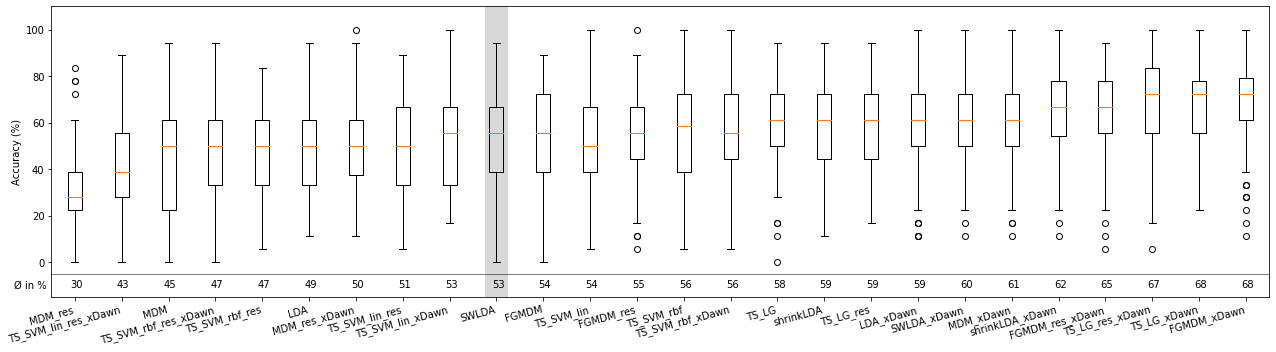

In [16]:
boxplot_accuracy(eight_epochs,r"All_conditions",r"all_conditions")

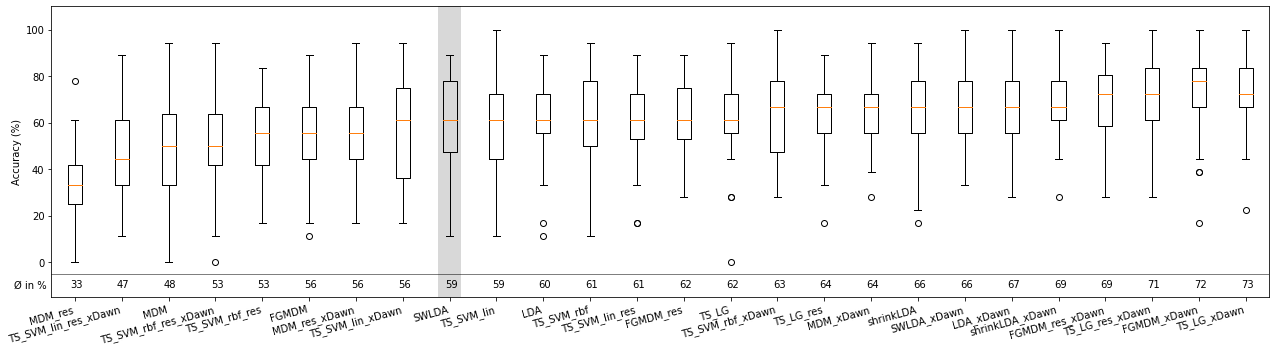

In [22]:
boxplot_accuracy(sess3,r"Sessionwise Calibration - 3 Runs",r"$\bf{Sessionwise}$ Calibration - $\bf{3}$ Runs")

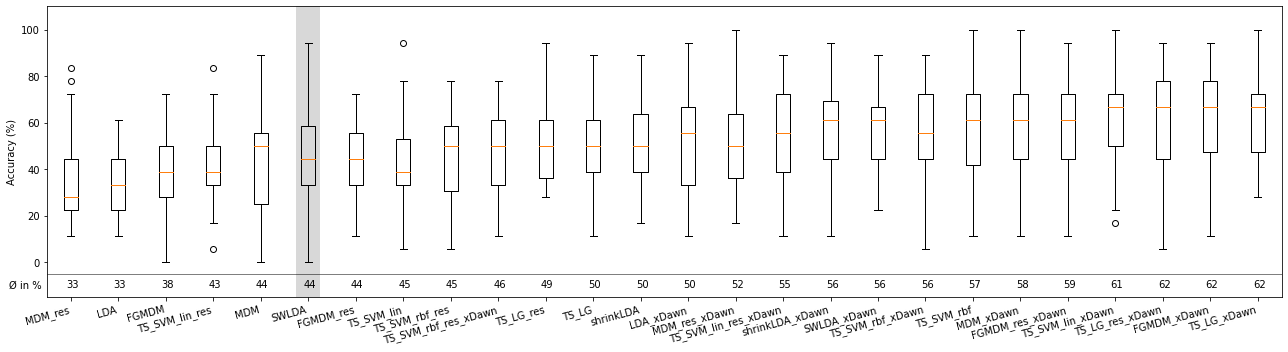

In [20]:
boxplot_accuracy(sess1,"Sessionwise Calibration - 1 Run",r"$\bf{Sessionwise}$ Calibration - $\bf{1}$ Run")

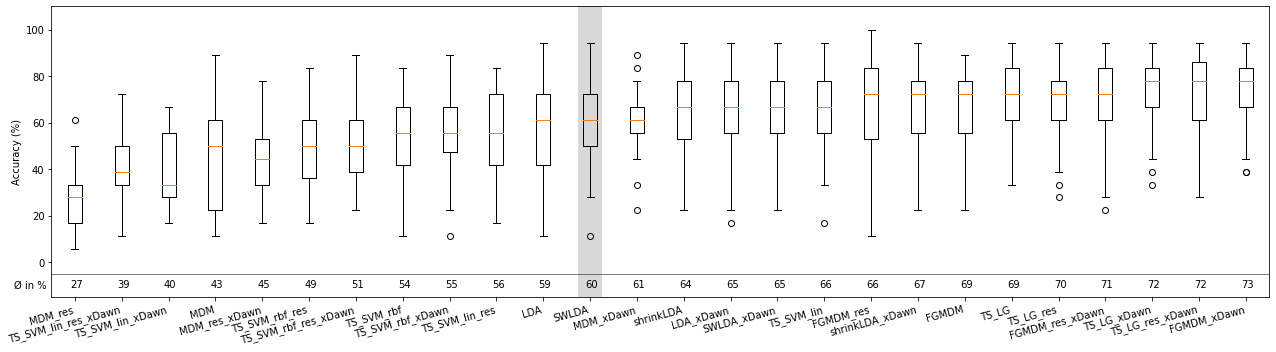

In [23]:
boxplot_accuracy(single3,r"Single Calibration - 3 Sessions (9 Runs)",r"$\bf{Single}$ Calibration - 3 Sessions ($\bf{9}$ Runs)")

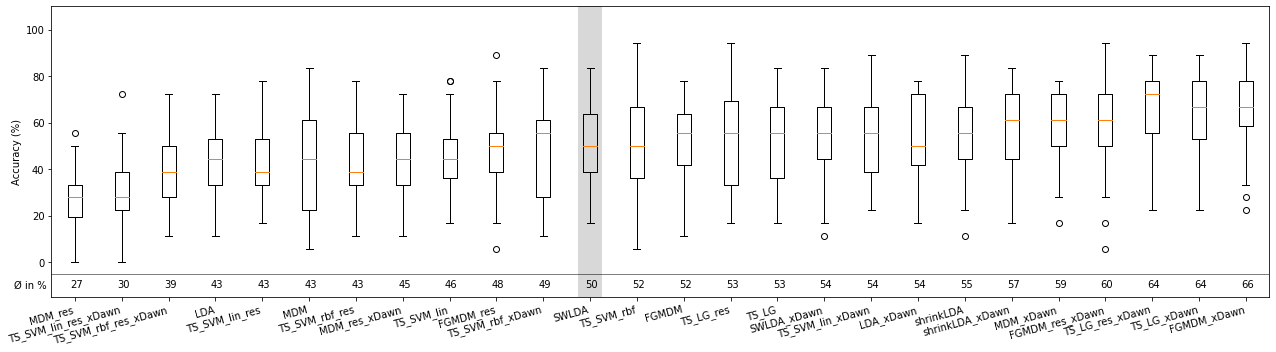

In [24]:
boxplot_accuracy(single1,r"Single Calibration - 1 Session (3 Runs)",r"$\bf{Single}$ Calibration - 1 Session ($\bf{3}$ Runs)")

### Boxplots Accuracy Portrait

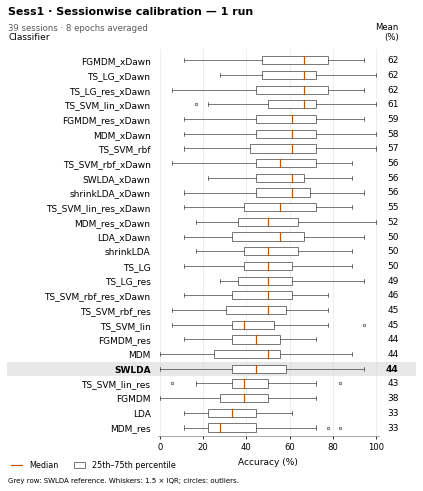

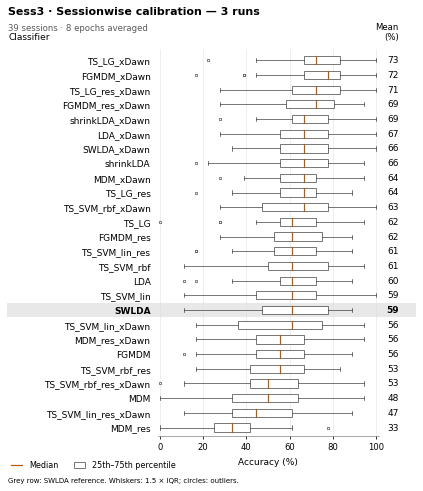

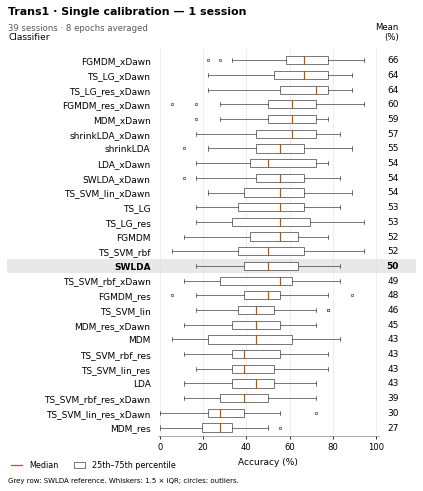

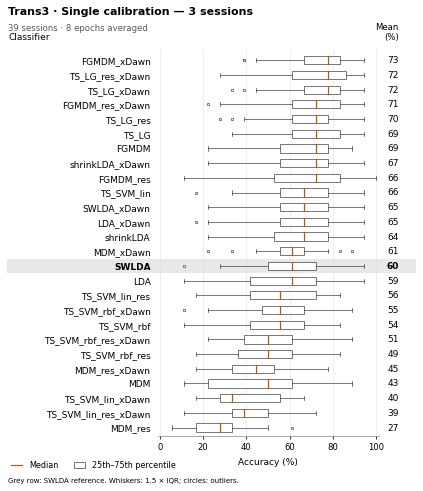

In [25]:
fig, ax = boxplot_accuracy_portrait(
    sess1,
    name="Sess1",
    fname="Sess1 · Sessionwise calibration — 1 run")

fig, ax = boxplot_accuracy_portrait(
    sess3,
    name="Sess3",
    fname="Sess3 · Sessionwise calibration — 3 runs")

fig, ax = boxplot_accuracy_portrait(
    single1,
    name="Trans1",
    fname="Trans1 · Single calibration — 1 session")

fig, ax = boxplot_accuracy_portrait(
    single3,
    name="Trans3",
    fname="Trans3 · Single calibration — 3 sessions")

### Classifies: Best/Worst - Sessionwise Ranking

In [26]:
def Per2Ac_BW(x):
    return x*5

def Ac2Per_BW(x):
    return x/5

1
0.7777777777777778
3183    TS_SVM_rbf_xDawn
Name: Classifier, dtype: object
___________________________________
2
0.6666666666666666
3191    SWLDA_xDawn
Name: Classifier, dtype: object
___________________________________
3
0.5555555555555556
3271    shrinkLDA_xDawn
Name: Classifier, dtype: object
___________________________________
4
nan
Series([], Name: Classifier, dtype: object)
___________________________________
5
0.4444444444444444
3319    SWLDA_xDawn
Name: Classifier, dtype: object
___________________________________
6
0.7222222222222222
3407           MDM_xDawn
3439    TS_SVM_rbf_xDawn
Name: Classifier, dtype: object
___________________________________
7
nan
Series([], Name: Classifier, dtype: object)
___________________________________
8
0.7777777777777778
207    MDM_res_xDawn
Name: Classifier, dtype: object
___________________________________
9
0.5555555555555556
3519          LDA_xDawn
3527    shrinkLDA_xDawn
Name: Classifier, dtype: object
_________________________________

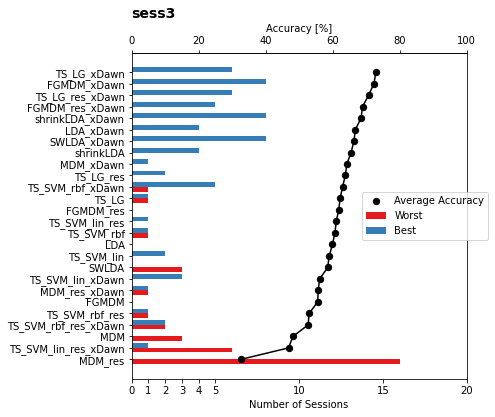

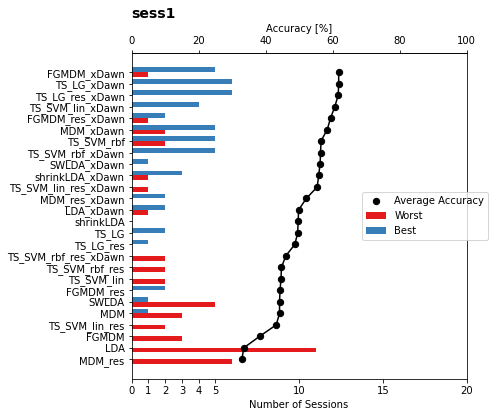

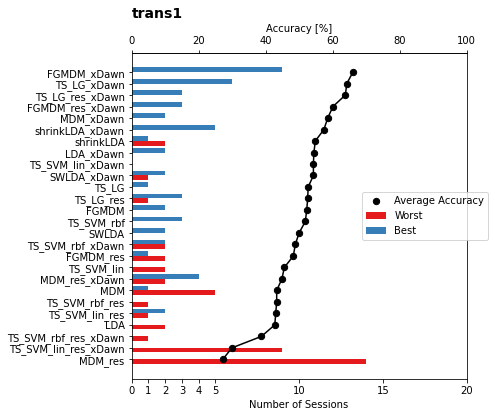

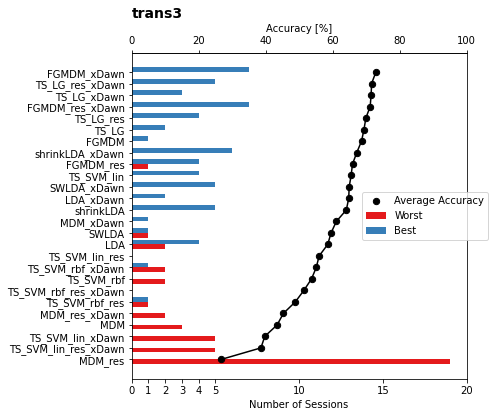

In [36]:
for condition in ["sess3","sess1","single1","single3"]:
    best_performance =pd.DataFrame(columns=["Classifier"])
    worst_performance =pd.DataFrame(columns=["Classifier"])
    for session in range(1,40):
        df = eval(condition).loc[(eval(condition).Ep2Avg==8) &(eval(condition).Session==session)]
        print(session)
        print(df.Accuracy.max())
        print(df.loc[df.Accuracy == df.Accuracy.max()]["Classifier"])
        print("___________________________________")
        best_performance = best_performance.append(df.loc[df.Accuracy == df.Accuracy.max()])
        worst_performance = worst_performance.append(df.loc[df.Accuracy == df.Accuracy.min()])
    performance = pd.DataFrame()
    performance["Accuracy"] = eval(condition).loc[(eval(condition).Ep2Avg==8)].groupby("Classifier").mean().sort_values("Accuracy")["Accuracy"]*20
    performance["Worst"] =worst_performance.groupby("Classifier").count().Accuracy
    performance["Best"] =best_performance.groupby("Classifier").count().Accuracy

    condition = "trans3" if condition == "single3" else condition
    condition = "trans1" if condition == "single1" else condition
    fig, ax = plt.subplots(figsize=(6,6))
    ax.set_title(condition, loc="left", fontsize=14, fontweight="bold", pad=35)
    col_list= ["#377eb8","#e41a1c","k"]
    #col_list= ["#d8b365","#5ab4ac","#ef8a62","#67a9cf"]
    y= np.arange(len(performance.index))
    height=0.8
    ax.barh(y- (height/4),performance.Worst, label="Worst",height=height/2, color =col_list[1])
    ax.barh(y+( height/4),performance.Best, label="Best",height=height/2,color =col_list[0])
    ax.scatter(performance.Accuracy,performance.index, alpha=1,label="Average Accuracy", marker ="o",color =col_list[2], s=40,zorder=4)
    ax.plot(performance.Accuracy,performance.index, alpha=1,color =col_list[2])
    ax.set_xticks([0,1,2,3,4,5,10,15,20])
    ax.set_xlabel("Number of Sessions")
    sec_ax = ax.secondary_xaxis("top",functions= (Per2Ac_BW,Ac2Per_BW))
    sec_ax.set_xlabel("Accuracy [%]")
    ax.legend()
    ax.legend(loc="center right", bbox_to_anchor=(1.08, 0.5))
    plt.savefig(r"results\figures\best_worst_"+condition+".png",bbox_inches="tight",pad_inches=0.2,format="png")




# ROC curves

In [16]:
all_roc = pd.read_csv(r"created_data\Classifier_Results\current\roc.csv")
all_roc["Condition"] = all_roc["Condition"].map({"sess3":"sess3","sess1":"sess1","single3_A":"single3","single3_B":"single3","single1_A":"single1","single1_B":"single1"}, na_action='ignore')
all_roc.to_csv(r"created_data\Classifier_Results\current\roc_rightlabel.csv",index=False)
all_roc["Condition"].isnull().any().sum()

FileNotFoundError: [Errno 2] No such file or directory: 'created_data\\Classifier_Results\\current\\roc.csv'

In [ ]:
for condition in np.unique(all_roc.Condition):
    k=0
    fig, ax = plt.subplots(5,2, figsize=(6,12))
    for i,classifier in enumerate(np.unique(all_roc.Classifier)):
        k = 1 if i>=5 else 0
        roc = all_roc.loc[(all_roc.Classifier==classifier) & (all_roc.Condition==condition)]
        roc["binnedTPR"] = pd.cut(roc.TPR,50)
        roc = roc.groupby("binnedTPR").mean().dropna()
        ax[i-(k*5)][k].plot(roc.FPR,roc.TPR)
        ax[i-(k*5)][k].plot([0,1],[0,1])
        title = classifier
        ax[i-(k*5)][k].title.set_text(title)
    fig.tight_layout()
    fig.suptitle(condition, y=1)
    plt.savefig(r"results/figures/roc_"+condition+".svg",bbox_inches="tight",pad_inches=0.2,format="svg")

In [ ]:
fig, ax = plt.subplots(2,2, figsize=(12,12))
for i,condition in enumerate(np.unique(all_roc.Condition)):
    k = 1 if i>=2 else 0
    ax[i-(k*2)][k].plot([0,1],[0,1], label = "random")
    for classifier in np.unique(all_roc.Classifier):
        roc = all_roc.loc[(all_roc.Classifier==classifier) & (all_roc.Condition==condition)]
        roc["binnedTPR"] = pd.cut(roc.TPR,50)
        roc = roc.groupby("binnedTPR").mean().dropna()
        ax[i-(k*2)][k].plot(roc.FPR,roc.TPR,label=classifier)
    ax[i-(k*2)][k].title.set_text(condition)
plt.legend()
fig.tight_layout()
plt.savefig(r"results/figures/roc.svg",bbox_inches="tight",pad_inches=0.2,format="svg")

In [ ]:
np.unique(all_roc.Classifier)